<a href="https://colab.research.google.com/github/jiieeeee/Rebortera_Activity-1/blob/main/Rebortera_LAB_EXAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, roc_auc_score)

df = pd.read_csv("telecom_churn (1).csv")
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")  # e.g. "account length" -> "account_length"
print(df.shape)
df.head()

(3333, 21)


,state,account_length,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,customer_service_calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [13]:

df.info()
print(df.isnull().sum())

for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype in ["int64", "float64"]:
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum().sum(), "missing values left")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account_length          3333 non-null   int64  
 2   area_code               3333 non-null   int64  
 3   phone_number            3333 non-null   object 
 4   international_plan      3333 non-null   object 
 5   voice_mail_plan         3333 non-null   object 
 6   number_vmail_messages   3333 non-null   int64  
 7   total_day_minutes       3333 non-null   float64
 8   total_day_calls         3333 non-null   int64  
 9   total_day_charge        3333 non-null   float64
 10  total_eve_minutes       3333 non-null   float64
 11  total_eve_calls         3333 non-null   int64  
 12  total_eve_charge        3333 non-null   float64
 13  total_night_minutes     3333 non-null   float64
 14  total_night_calls       3333 non-null   

In [14]:

df["churn"] = df["churn"].astype(int)


df = df.drop(columns=["phone_number"])


df["area_code"] = df["area_code"].astype(str)


cat_cols = df.select_dtypes(include=["object", "bool"]).columns.tolist()
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

X = df.drop("churn", axis=1)
y = df["churn"]
print(X.shape)
print(y.value_counts(normalize=True))

(3333, 69)
churn
0    0.855086
1    0.144914
Name: proportion, dtype: float64


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(2666, 69) (667, 69)
churn
0    0.855214
1    0.144786
Name: proportion, dtype: float64
churn
0    0.854573
1    0.145427
Name: proportion, dtype: float64


In [16]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

log_reg.fit(X_train_scaled, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

print("All 3 models trained.")

All 3 models trained.


In [17]:
models = {
    "Logistic Regression": (log_reg, X_test_scaled),
    "Decision Tree": (dt, X_test),
    "Random Forest": (rf, X_test),
}

results = {}
probs = {}

for name, (model, X_t) in models.items():
    y_pred = model.predict(X_t)
    y_prob = model.predict_proba(X_t)[:, 1]   # predicted probabilities of churn
    probs[name] = y_prob

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
    }

    print(f"\n{name} - Confusion Matrix (rows = actual, cols = predicted):")
    print(confusion_matrix(y_test, y_pred))

summary = pd.DataFrame(results).round(4)
summary.index.name = "Metric"
print("\nComparative Summary Table:")
summary


Logistic Regression - Confusion Matrix (rows = actual, cols = predicted):
[[548  22]
 [ 71  26]]

Decision Tree - Confusion Matrix (rows = actual, cols = predicted):
[[550  20]
 [ 37  60]]

Random Forest - Confusion Matrix (rows = actual, cols = predicted):
[[568   2]
 [ 80  17]]

Comparative Summary Table:


,Logistic Regression,Decision Tree,Random Forest
Metric,,,
Accuracy,0.8606,0.9145,0.8771
Precision,0.5417,0.7500,0.8947
Recall,0.2680,0.6186,0.1753
F1-Score,0.3586,0.6780,0.2931


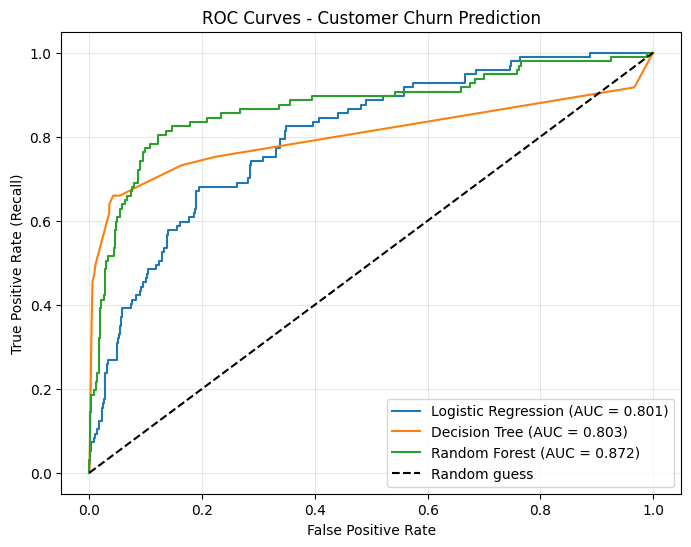

In [18]:
plt.figure(figsize=(8, 6))

for name, y_prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves - Customer Churn Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()